In [21]:
import pandas as pd

df = pd.read_csv("/clickbait_data.csv")

print(df.shape)

(32000, 2)


In [5]:
# Dataset information

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape:
(32000, 2)

Column Names:
Index(['headline', 'clickbait'], dtype='object')

Data Types:
headline     object
clickbait     int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32000 entries, 0 to 31999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   headline   32000 non-null  object
 1   clickbait  32000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 500.1+ KB


In [6]:
# Five random samples

df.sample(5, random_state=42)

,headline,clickbait
23100,Filipino activist arrested for disrupting Mani...,0
17362,"International Board fixes soccer field size, h...",0
8993,24 Rules For Women On A First Date With A Man,1
19566,Political fallout from the sacking of Professo...,0
3798,"Which ""Clueless"" Character Are You Based On Yo...",1


In [7]:
# Check missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
headline     0
clickbait    0
dtype: int64


In [8]:
# Check duplicate rows

print("Number of duplicate rows:")
print(df.duplicated().sum())

Number of duplicate rows:
0


### Missing and Duplicate Data

The dataset contains no missing values and no exact duplicate rows. Therefore, no rows need to be removed at this stage. The headline text will be preserved because punctuation, capitalization, and wording may provide useful information for clickbait detection.

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

clickbait
0    16001
1    15999
Name: count, dtype: int64


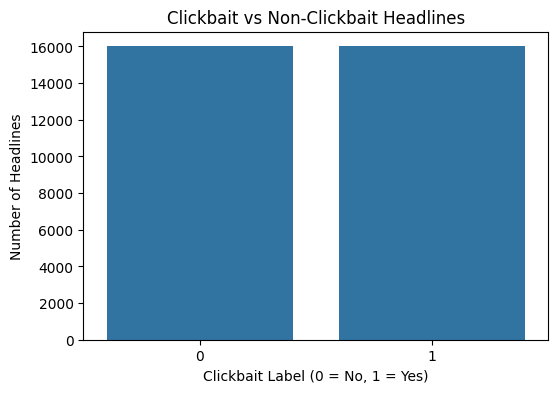

In [13]:
# Class distribution

print(df["clickbait"].value_counts())

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="clickbait")

plt.title("Clickbait vs Non-Clickbait Headlines")
plt.xlabel("Clickbait Label (0 = No, 1 = Yes)")
plt.ylabel("Number of Headlines")

plt.show()

### Class Distribution

The dataset contains two classes: non-clickbait (0) and clickbait (1). The classes are almost perfectly balanced, with 16,001 non-clickbait headlines and 15,999 clickbait headlines. Therefore, severe class imbalance is not expected to affect the initial model. Accuracy, precision, recall, F1-score, and a confusion matrix should still be used to evaluate the model.

In [14]:
# Calculate headline length

df["char_length"] = df["headline"].str.len()

df["word_length"] = df["headline"].str.split().str.len()

print("Character length statistics:")
print(df["char_length"].describe())

print("\nWord length statistics:")
print(df["word_length"].describe())

Character length statistics:
count    32000.000000
mean        53.797063
std         14.771455
min          6.000000
25%         44.000000
50%         52.000000
75%         63.000000
max        135.000000
Name: char_length, dtype: float64

Word length statistics:
count    32000.000000
mean         9.065156
std          2.603603
min          1.000000
25%          7.000000
50%          9.000000
75%         11.000000
max         26.000000
Name: word_length, dtype: float64


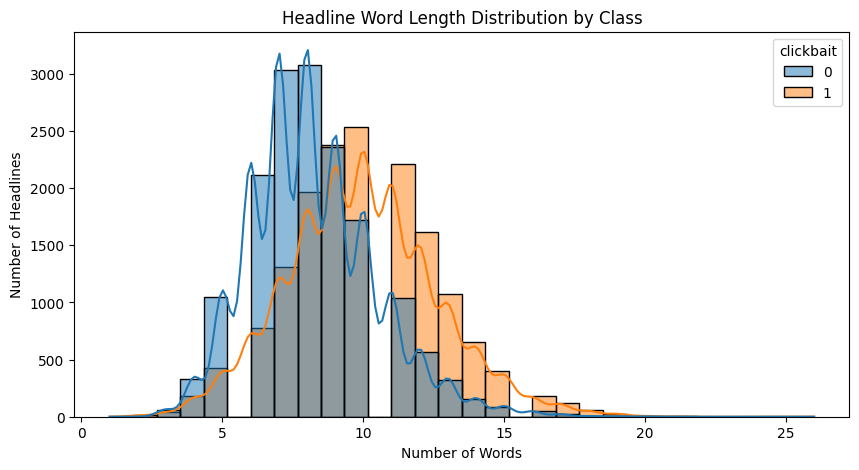

In [15]:
# Plot headline lengths

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_length",
    hue="clickbait",
    bins=30,
    kde=True
)

plt.title("Headline Word Length Distribution by Class")
plt.xlabel("Number of Words")
plt.ylabel("Number of Headlines")

plt.show()

### Headline Length Analysis

The word-length distribution shows how long the headlines are in each class. This analysis is useful for selecting the maximum sequence length for an LSTM or CNN model. Very short headlines may contain limited context, while longer headlines may provide more linguistic information. The model's sequence length should be selected based on the observed distribution rather than choosing an arbitrary value.

In [16]:
# Vocabulary analysis

all_words = " ".join(df["headline"].astype(str)).lower().split()

vocabulary = set(all_words)

print("Total number of words:", len(all_words))
print("Vocabulary size:", len(vocabulary))

Total number of words: 290085
Vocabulary size: 30340


In [17]:
from collections import Counter

word_counts = Counter(all_words)

print("Top 30 most frequent words:")

for word, count in word_counts.most_common(30):
    print(word, ":", count)

Top 30 most frequent words:
to : 6656
in : 6466
the : 6149
of : 5100
you : 4828
a : 3961
for : 3163
and : 2814
on : 2759
your : 2578
is : 2128
are : 2110
that : 1904
this : 1851
with : 1609
at : 1542
will : 1382
from : 1357
new : 1226
about : 1158
what : 1139
who : 1015
things : 997
people : 992
how : 934
which : 901
as : 833
can : 819
make : 809
we : 809


### Vocabulary Analysis

The vocabulary analysis identifies the number of unique words and the most frequent words in the dataset. Frequent words may represent common headline language. This information can help determine the vocabulary size for a neural network tokenizer and identify words that may be useful for distinguishing clickbait from non-clickbait headlines.

In [18]:
# Noise audit

import re

def check_url(text):
    return bool(re.search(r"https?://|www\.", str(text), re.IGNORECASE))

def check_question_mark(text):
    return "?" in str(text)

def check_exclamation_mark(text):
    return "!" in str(text)

df["has_url"] = df["headline"].apply(check_url)

df["has_question_mark"] = df["headline"].apply(check_question_mark)

df["has_exclamation_mark"] = df["headline"].apply(check_exclamation_mark)

print("Headlines containing URLs:")
print(df["has_url"].sum())

print("\nHeadlines containing question marks:")
print(df["has_question_mark"].sum())

print("\nHeadlines containing exclamation marks:")
print(df["has_exclamation_mark"].sum())

Headlines containing URLs:
0

Headlines containing question marks:
160

Headlines containing exclamation marks:
38


### Noise Audit

The noise audit checks for URLs, question marks, and exclamation marks in the headline text. Punctuation such as question marks and exclamation marks may be important clickbait indicators because clickbait headlines often use curiosity, surprise, and emotional language. Therefore, punctuation should not be removed automatically. Different preprocessing methods can be compared during model development.

## 13. Dataset Card

### Dataset Name

Clickbait Headline Detection Dataset

### Source

The dataset is provided as a CSV file named `clickbait_data.csv`. The original public source link should be added after confirming the dataset's source.

### Licence

The licence is not specified in the supplied CSV file. It should be confirmed from the original dataset source before publication.

### Size on Disk

Approximately 1.84 MB.

### Number of Samples

The dataset contains 32,000 headline records.

### Data Collection

The dataset contains headline text with binary clickbait labels. The exact collection and annotation process is not documented in the supplied CSV file.

### Known Limitations

The dataset may contain source-specific writing styles, imperfect labels, and distribution differences from modern online headlines. It may not represent every type of clickbait headline. The dataset does not include publisher, author, or timestamp information, so group-based leakage checks cannot be performed.


In [19]:
# Train / Validation / Test Split

from sklearn.model_selection import train_test_split

X = df["headline"]
y = df["clickbait"]

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 22400
Validation samples: 4800
Testing samples: 4800


### Train / Validation / Test Split Plan

The dataset will be divided into 70% training, 15% validation, and 15% testing data. A stratified split is used because the target contains two classes: clickbait and non-clickbait. Stratification preserves a similar class distribution in all three subsets.

The training set will be used to train the model, the validation set will be used for selecting model settings, and the test set will be used for final evaluation. Since the dataset does not provide publisher, author, or timestamp identifiers, a group-based or time-based split cannot be performed.


In [20]:
# Three findings from the dataset

print("Finding 1: Headline length")
print("Headline length will help us choose the maximum sequence length for an LSTM or CNN model.")

print("\nFinding 2: Punctuation")
print("Question marks and exclamation marks may contain useful clickbait signals, so punctuation should be preserved in one baseline.")

print("\nFinding 3: Balanced classes")
print("The dataset is nearly balanced, so class weighting is not required initially. We can focus on linguistic features and model performance.")

Finding 1: Headline length
Headline length will help us choose the maximum sequence length for an LSTM or CNN model.

Finding 2: Punctuation
Question marks and exclamation marks may contain useful clickbait signals, so punctuation should be preserved in one baseline.

Finding 3: Balanced classes
The dataset is nearly balanced, so class weighting is not required initially. We can focus on linguistic features and model performance.


In [22]:
print("""
DATASET CARD
------------
Source: Kaggle - "Clickbait Dataset" (amananandrai), derived from
        Chakraborty, Paranjape, Kakarla & Ganguly (2016), "Stop Clickbait:
        Detecting and Preventing Clickbaits in Online News Media", ASONAM 2016.
Link: https://www.kaggle.com/datasets/amananandrai/clickbait-dataset
License: Public domain / CC0 (as listed on Kaggle) - for coursework use.
Size on disk: ~1.8 MB (single CSV)
Samples: 32,000 headlines (16,001 non-clickbait, 15,999 clickbait)
Collection: Clickbait headlines scraped from BuzzFeed, Upworthy, ViralNova,
            Thatscoop, Scoopwhoop, ViralStories. Non-clickbait headlines from
            WikiNews, New York Times, The Guardian, The Hindu. Each headline
            manually labeled by at least 3 annotators (per original paper).
Known limitations:
  - English-only headlines; no multilingual/Nepali content to audit.
  - Source-site bias: model may learn "site style" rather than pure
    clickbait linguistic signal (e.g. BuzzFeed formatting vs NYT formatting).
  - No article body, images, or engagement metrics - headline text only.
  - Headlines from 2016 or earlier; internet clickbait style has since evolved.
""")


DATASET CARD
------------
Source: Kaggle - "Clickbait Dataset" (amananandrai), derived from
        Chakraborty, Paranjape, Kakarla & Ganguly (2016), "Stop Clickbait:
        Detecting and Preventing Clickbaits in Online News Media", ASONAM 2016.
Link: https://www.kaggle.com/datasets/amananandrai/clickbait-dataset
License: Public domain / CC0 (as listed on Kaggle) - for coursework use.
Size on disk: ~1.8 MB (single CSV)
Samples: 32,000 headlines (16,001 non-clickbait, 15,999 clickbait)
Collection: Clickbait headlines scraped from BuzzFeed, Upworthy, ViralNova,
            Thatscoop, Scoopwhoop, ViralStories. Non-clickbait headlines from
            WikiNews, New York Times, The Guardian, The Hindu. Each headline
            manually labeled by at least 3 annotators (per original paper).
Known limitations:
  - English-only headlines; no multilingual/Nepali content to audit.
  - Source-site bias: model may learn "site style" rather than pure
    clickbait linguistic signal (e.g. BuzzFee

In [23]:
# Corrupt / degenerate entries
empty_or_whitespace = df["headline"].astype(str).str.strip().eq("").sum()
non_string_rows = (~df["headline"].apply(lambda x: isinstance(x, str))).sum()
very_short = (df["headline"].astype(str).str.split().str.len() <= 1).sum()

print("Empty/whitespace-only headlines:", empty_or_whitespace)
print("Non-string entries:", non_string_rows)
print("Headlines with <=1 word (likely truncated/corrupt):", very_short)

# Action: none found in this dataset (0 missing, 0 duplicates, 0 empty) -
# so no cleaning/imputation is required before modeling.

Empty/whitespace-only headlines: 0
Non-string entries: 0
Headlines with <=1 word (likely truncated/corrupt): 1


In [24]:
print("""
Imbalance comment: classes are 16,001 vs 15,999 - effectively a 50/50
split (<0.01% skew). This means accuracy is a safe metric here (unlike
a 90/10 dataset where accuracy would be misleading), no class weighting
or resampling (SMOTE/undersampling) is needed, and the model won't be
biased toward predicting one label by default.
""")


Imbalance comment: classes are 16,001 vs 15,999 - effectively a 50/50
split (<0.01% skew). This means accuracy is a safe metric here (unlike
a 90/10 dataset where accuracy would be misleading), no class weighting
or resampling (SMOTE/undersampling) is needed, and the model won't be
biased toward predicting one label by default.



In [27]:
# Per-class length + vocabulary (self-contained, doesn't depend on earlier cells)
df["word_length"] = df["headline"].astype(str).str.split().str.len()
df["char_length"] = df["headline"].astype(str).str.len()

from collections import Counter

for label, name in [(0, "Non-clickbait"), (1, "Clickbait")]:
    sub = df[df["clickbait"] == label]
    print(f"\n--- {name} ---")
    print("Word length:", sub["word_length"].describe()[["mean", "std", "min", "max"]].to_dict())
    print("Char length mean:", sub["char_length"].mean().round(1))
    words = " ".join(sub["headline"].astype(str)).lower().split()
    print("Vocabulary size:", len(set(words)))
    print("Top 15 words:", Counter(words).most_common(15))


--- Non-clickbait ---
Word length: {'mean': 8.188613211674271, 'std': 2.2248141119986595, 'min': 2.0, 'max': 21.0}
Char length mean: 51.9
Vocabulary size: 21525
Top 15 words: [('in', 4550), ('to', 3417), ('of', 2666), ('for', 1769), ('the', 1417), ('a', 1352), ('on', 1306), ('and', 1167), ('at', 1056), ('new', 797), ('after', 655), ('with', 650), ('us', 598), ('as', 544), ('by', 537)]

--- Clickbait ---
Word length: {'mean': 9.941808863053941, 'std': 2.65919356516613, 'min': 1.0, 'max': 26.0}
Char length mean: 55.7
Vocabulary size: 14415
Top 15 words: [('you', 4807), ('the', 4732), ('to', 3239), ('a', 2609), ('your', 2538), ('of', 2434), ('are', 1940), ('in', 1916), ('this', 1804), ('that', 1781), ('and', 1647), ('is', 1627), ('on', 1453), ('for', 1394), ('will', 1242)]


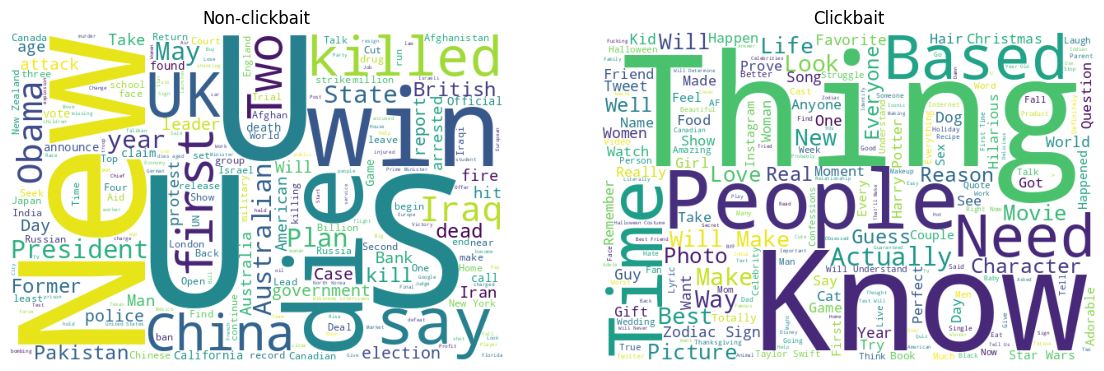

In [28]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, label, name in zip(axes, [0, 1], ["Non-clickbait", "Clickbait"]):
    text = " ".join(df[df["clickbait"] == label]["headline"].astype(str))
    wc = WordCloud(width=600, height=400, background_color="white").generate(text)
    ax.imshow(wc)
    ax.set_title(name)
    ax.axis("off")
plt.show()

In [29]:
print("""
Finding 1: Clickbait headlines average ~9.9 words vs ~8.2 for
non-clickbait (about 20% longer), with higher variance (std 2.66 vs
2.22). Word/char length is a genuinely discriminating signal, not just
a preprocessing detail - a simple length feature alone would beat
random guessing.

Finding 2: Non-clickbait headlines come from formal news outlets
(NYT, Guardian, WikiNews) and clickbait from entertainment sites
(BuzzFeed, Upworthy). This means the model may be partly learning
"newsroom style vs BuzzFeed style" rather than a general notion of
clickbait - so I expect it to generalize poorly to clickbait headlines
from other formal-sounding sources (e.g. clickbait-y headlines from a
legitimate outlet's entertainment section).

Finding 3: The near-exact 50/50 balance (16,001 vs 15,999) means I can
skip class weighting entirely and use plain accuracy/F1 as my headline
metric, simplifying the training loop compared to an imbalanced task.
""")


Finding 1: Clickbait headlines average ~9.9 words vs ~8.2 for
non-clickbait (about 20% longer), with higher variance (std 2.66 vs
2.22). Word/char length is a genuinely discriminating signal, not just
a preprocessing detail - a simple length feature alone would beat
random guessing.

Finding 2: Non-clickbait headlines come from formal news outlets
(NYT, Guardian, WikiNews) and clickbait from entertainment sites
(BuzzFeed, Upworthy). This means the model may be partly learning
"newsroom style vs BuzzFeed style" rather than a general notion of
clickbait - so I expect it to generalize poorly to clickbait headlines
from other formal-sounding sources (e.g. clickbait-y headlines from a
legitimate outlet's entertainment section).

Finding 3: The near-exact 50/50 balance (16,001 vs 15,999) means I can
skip class weighting entirely and use plain accuracy/F1 as my headline
metric, simplifying the training loop compared to an imbalanced task.

